## Most frequent place per monarch

Counts how often each place from `holinshed_places.csv` (confidence ≥ 0.75) occurs in each `regnal_entry` of `monarchs_reign.xml`, then shows the top place per reign.

Margin notes (mostly source citations like "Math. Paris") and titles like "Duke of Yorke" are removed before counting.

Spellings are matched by a normalized key (`VVestmynster` = `Westminster`, `Normãdye` = `Normandie`, `Oxforde` = `Oxford`), and one-word names must start with a capital letter so common words like "seeme" or "mercy" are not counted as places.

In [1]:
import re
import unicodedata
import pandas as pd
import matplotlib.pyplot as plt
from lxml import etree

def norm(word):
    """Spelling key for one word, so early-modern variants match: Normãdye -> Normandi, VVestmynster -> Westminster."""
    word = word.replace("ã", "an").replace("õ", "on").replace("ẽ", "en").replace("ũ", "un")
    word = unicodedata.normalize("NFKD", word).encode("ascii", "ignore").decode()
    key = word.lower().replace("vv", "w").replace("j", "i").replace("v", "u").replace("y", "i")
    key = re.sub(r"au(?=n)", "a", key)  # Fraunce -> France
    key = re.sub(r"(.)\1", r"\1", key)  # doubled letters
    key = re.sub(r"e$", "", key)  # final e
    return key.capitalize() if word[:1].isupper() else key

def norm_text(text):
    return re.sub(r"[^\W\d_]+", lambda m: norm(m.group()), text)

places = pd.read_csv("../name_extraction/entity_names/holinshed_places.csv")
places = places[places["confidence"] >= 0.75].sort_values("confidence", ascending=False)

# Merge rows with the same spelling key (Scotland / Scotlande, Normandy / Normandie);
# the highest-confidence name becomes the label
places["spellings"] = places["name"] + "|" + places["spelling_variants"]
places = places.groupby(places["name"].map(norm_text).str.lower()).agg(
    name=("name", "first"), spellings=("spellings", "|".join)
)

def place_pattern(spellings):
    keys = sorted({norm_text(s.strip()).lower() for s in spellings.split("|") if s.strip()}, key=len, reverse=True)
    # One-word names must start with a capital (skips "seeme", "mercy", ...); multi-word names
    # ignore case ("the tower of London")
    return re.compile(r"(?<!\w)(?:" + "|".join(
        f"(?i:{re.escape(k)})" if " " in k else k[0].upper() + f"(?i:{re.escape(k[1:])})" for k in keys
    ) + r")(?!\w)")

patterns = {row["name"]: place_pattern(row["spellings"]) for _, row in places.iterrows()}
print(f"{len(patterns)} places")

851 places


In [2]:
TEI = {"t": "http://www.tei-c.org/ns/1.0"}
root = etree.parse("../1577_files/monarchs_reign.xml").getroot()
etree.strip_elements(root, "{http://www.tei-c.org/ns/1.0}note", with_tail=False)  # drop margin notes

# Titles name people, not places: "Duke of Yorke", "Bishop of London", ...
TITLES = re.compile(r"\b(?:arch)?(?:duke|duches|earle|erle|countesse|marques|bishop|abbot)s? of \w+", re.IGNORECASE)

counts = {}
for div in root.iterfind(".//t:div[@type='regnal_entry']", TEI):
    text = re.sub(r"\s+", " ", " ".join(div.itertext()).replace("ſ", "s"))  # join names split across lines
    text = norm_text(TITLES.sub("", text))
    counts[div.get("n")] = {name: len(p.findall(text)) for name, p in patterns.items()}

counts = pd.DataFrame(counts)  # rows: places, columns: monarchs (in text order)
counts.shape

(851, 23)

In [3]:
top = pd.DataFrame({"place": counts.idxmax(), "occurrences": counts.max()})
top

,place,occurrences
WilliamConqueror,york,21
WilliamRufus,Normandy,29
HenryFIrst,Normandy,49
Stephen,Normandy,22
Henry II,Normandy,76
Richard I,york,36
John,London,54
Henry III,London,166
Edward I,Scotland,132
EdwardII,London,36


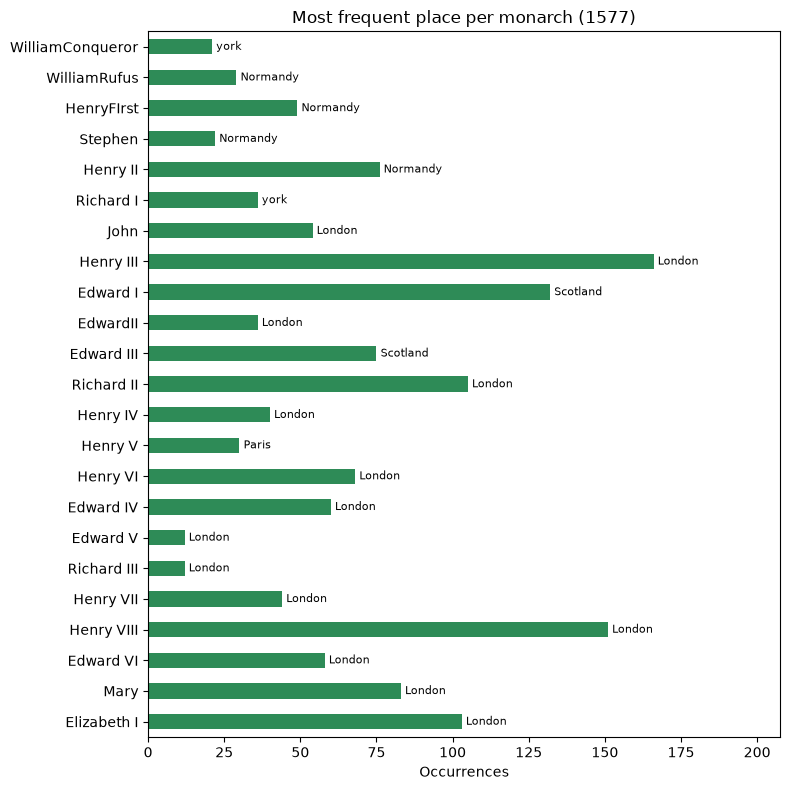

In [4]:
ax = top["occurrences"].plot.barh(figsize=(8, 8), color="seagreen")
ax.invert_yaxis()
ax.bar_label(ax.containers[0], labels=top["place"], padding=3, fontsize=8)
ax.set(title="Most frequent place per monarch (1577)", xlabel="Occurrences", ylabel="")
ax.set_xlim(0, top["occurrences"].max() * 1.25)
plt.tight_layout()
plt.show()

## Top places across reigns

The 8 places with the most mentions overall, tracked reign by reign.

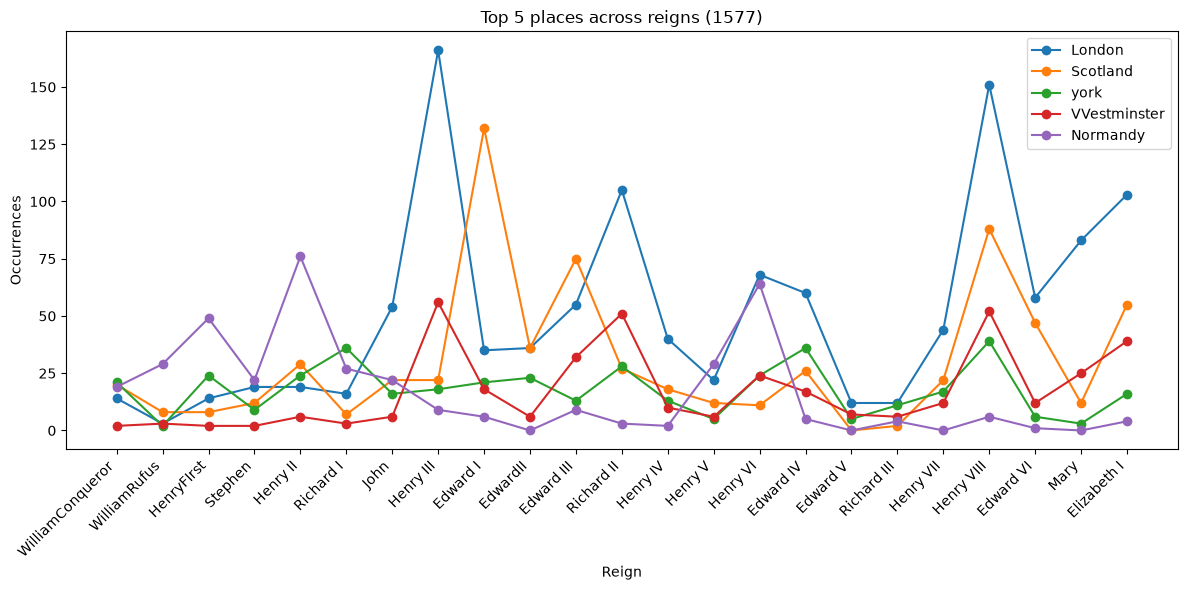

In [5]:
top_places = counts.sum(axis=1).nlargest(5).index
ax = counts.loc[top_places].T.plot(figsize=(12, 6), marker="o")
ax.set(title="Top 5 places across reigns (1577)", xlabel="Reign", ylabel="Occurrences")
ax.set_xticks(range(len(counts.columns)), counts.columns, rotation=45, ha="right")
plt.tight_layout()
plt.show()